# NIO Stock Analysis

- Company: NIO Inc.
- Stock ticker: NIO
- Requested analysis period: January 1, 2026–October 12, 2026
- Observed trading days: January 2, 2026–October 9, 2026 (194 records)
- Data source: Yahoo Finance through yfinance
- Prices: Adjusted closing prices in USD

## Research Question

How did NIO's stock price and daily return volatility change during
the analysis period, and what business events may explain a
significant stock price movement?

In [1]:
%pip install pandas yfinance matplotlib

In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

print("Tools imported successfully.")

Tools imported successfully.


In [3]:
TICKER = "NIO"
START_DATE = "2026-01-01"
END_DATE = "2026-10-12"

nio = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)

if nio.empty:
    raise ValueError("No data downloaded. Check the connection and settings.")

nio.head()

Price,Close,High,Low,Open,Volume
Ticker,NIO,NIO,NIO,NIO,NIO
Date,,,,,
2026-01-02,5.14,5.38,5.08,5.32,40391000
2026-01-05,4.86,5.01,4.85,5.01,74650200
2026-01-06,4.78,5.04,4.74,4.96,61127400
2026-01-07,4.79,4.84,4.76,4.81,34014400
2026-01-08,4.73,4.85,4.67,4.85,33792600


In [4]:
if isinstance(nio.columns, pd.MultiIndex):
    nio = nio.xs(TICKER, axis=1, level="Ticker")

nio = nio.sort_index()
nio.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,5.14,5.38,5.08,5.32,40391000
2026-01-05,4.86,5.01,4.85,5.01,74650200
2026-01-06,4.78,5.04,4.74,4.96,61127400
2026-01-07,4.79,4.84,4.76,4.81,34014400
2026-01-08,4.73,4.85,4.67,4.85,33792600


In [5]:
print("First trading date:", nio.index.min().date())
print("Last trading date:", nio.index.max().date())
print("Number of rows:", len(nio))

display(nio.tail())

First trading date: 2026-01-02
Last trading date: 2026-10-09
Number of rows: 194


Price,Close,High,Low,Open,Volume
Date,,,,,
2026-10-05,3.42,3.47,3.40,3.42,26310800
2026-10-06,3.48,3.52,3.40,3.42,30394900
2026-10-07,3.54,3.55,3.43,3.45,25766400
2026-10-08,3.41,3.49,3.36,3.49,39765400
2026-10-09,3.58,3.63,3.48,3.49,44006200


In [6]:
print("Columns:", nio.columns.tolist())

print("\nData types:")
print(nio.dtypes)

print("\nMissing values:")
print(nio.isna().sum())

print("\nDuplicate dates:", nio.index.duplicated().sum())

Columns: ['Close', 'High', 'Low', 'Open', 'Volume']

Data types:
Price
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Missing values:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Duplicate dates: 0


## Data Inspection

The downloaded NIO dataset contains 194 daily records, covering
January 2, 2026 to October 9, 2026. Each row represents one trading day.

The columns are Close, High, Low, Open, and Volume. Price columns
are stored as floating-point numbers, while Volume is stored as
integers. No missing values or duplicate dates were found in the
downloaded data.

The dataset includes trading days only. Prices are adjusted because
auto_adjust=True was used during the download.

## Daily Returns

Daily return measures the percentage change in adjusted closing
price from the previous trading day.

Daily return (%) = (Current close / Previous close - 1) × 100

The first return is missing because the downloaded dataset has
no previous trading day's closing price for that observation.

In [7]:
nio["Daily_Return_Pct"] = (
    nio["Close"].pct_change(fill_method=None) * 100
)

display(nio[["Close", "Daily_Return_Pct"]].head())

Price,Close,Daily_Return_Pct
Date,,
2026-01-02,5.14,NaN
2026-01-05,4.86,-5.447466
2026-01-06,4.78,-1.646089
2026-01-07,4.79,0.209200
2026-01-08,4.73,-1.252608


Returns are calculated using all observations in the analysis
period. The first five rows below are shown only to check the calculation.

In [8]:
nio_stats = nio[["Close", "Daily_Return_Pct"]].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

nio_stats.columns = [
    "Adjusted Close (USD)",
    "Daily Return (%)"
]

display(nio_stats.round(2))

,Adjusted Close (USD),Daily Return (%)
count,194.00,193.00
mean,5.01,-0.14
median,4.90,-0.38
min,3.37,-7.81
max,6.87,15.38
std,0.83,3.24


## Descriptive Statistics

NIO has 194 adjusted closing-price observations and 193 valid daily
returns. The first daily return is missing because no previous
closing price is available within the downloaded dataset.

The mean adjusted closing price was $5.01, and the median was $4.90.
Adjusted closing prices ranged from $3.37 to $6.87, with a standard
deviation of $0.83.

Daily returns ranged from -7.81% to 15.38%. The mean daily return
was approximately -0.14%, while the median was -0.38%. The standard
deviation was 3.24 percentage points, describing the spread of
daily returns during the analysis period.

The mean daily return is an arithmetic average, not the total
return over the analysis period.

In [9]:
nio_monthly = nio["Close"].groupby(
    nio.index.to_period("M")
).agg(["count", "mean"])

nio_monthly.columns = [
    "Trading Days",
    "Average Adjusted Close (USD)"
]

display(nio_monthly.round(2))

,Trading Days,Average Adjusted Close (USD)
Date,,
2026-01,20,4.72
2026-02,19,4.93
2026-03,22,5.46
2026-04,21,6.40
2026-05,20,5.84
2026-06,21,5.24
2026-07,22,4.82
2026-08,21,4.55
2026-09,21,3.67


## Monthly Average Prices

NIO's average adjusted closing price increased from $4.72 in
January to $6.40 in April, the highest monthly average among
the complete months analyzed.

After April, the monthly average declined each month, reaching
$3.67 in September, the lowest average among the complete months.

October's average was $3.46, based on only seven trading days
through October 9. It represents a partial month.

These figures describe monthly average price levels, not monthly
returns, and do not explain the causes of the price changes.

## Significant Price Movement

We now look for one single large movement and try to explain it.

To keep this comparable with the Tesla and BYD notebooks, we select the trading
day with the **largest absolute daily return**, rather than choosing a date by
hand. Using the absolute value means the method does not assume in advance
whether we are looking for a gain or a loss.

In [10]:
event_date = nio["Daily_Return_Pct"].abs().idxmax()
event_position = nio.index.get_loc(event_date)

previous_close = nio["Close"].iloc[event_position - 1]
event_close = nio.loc[event_date, "Close"]

print("Largest absolute daily move:", event_date.date())
print("Daily return (%):", round(nio.loc[event_date, "Daily_Return_Pct"], 2))
print("Previous close (USD):", round(previous_close, 2))
print("Event-day close (USD):", round(event_close, 2))

nio.loc[[event_date], ["Close", "Daily_Return_Pct", "Volume"]]

Largest absolute daily move: 2026-03-10
Daily return (%): 15.38
Previous close (USD): 4.94
Event-day close (USD): 5.7


Price,Close,Daily_Return_Pct,Volume
Date,,,
2026-03-10,5.7,15.38461,147968700


The selected day is **March 10, 2026**, when NIO gained 15.38%, its largest
absolute daily move of the study period. We next look at the five trading days
before and after it to see whether the move happened in isolation or as part of
a longer directional change.

In [11]:
event_window = nio.iloc[
    max(0, event_position - 5):event_position + 6
]

print("Window start:", event_window.index.min().date())
print("Window end:", event_window.index.max().date())
print(
    "Highest close (USD):",
    round(event_window["Close"].max(), 2),
    "on",
    event_window["Close"].idxmax().date()
)
print(
    "Lowest close (USD):",
    round(event_window["Close"].min(), 2),
    "on",
    event_window["Close"].idxmin().date()
)

display(event_window[["Close", "Daily_Return_Pct", "Volume"]].round(2))

Window start: 2026-03-03
Window end: 2026-03-17
Highest close (USD): 6.03 on 2026-03-16
Lowest close (USD): 4.59 on 2026-03-03


Price,Close,Daily_Return_Pct,Volume
Date,,,
2026-03-03,4.59,-2.75,48562900
2026-03-04,4.84,5.45,52718100
2026-03-05,4.72,-2.48,40353800
2026-03-06,4.78,1.27,28381800
2026-03-09,4.94,3.35,44238200
2026-03-10,5.70,15.38,147968700
2026-03-11,5.47,-4.04,78327700
2026-03-12,5.55,1.46,57170600
2026-03-13,5.86,5.59,58201900


### Event Evidence: March 10, 2026 — Data Description

NIO's adjusted closing price rose from **\$4.94 on March 9** to
**\$5.70 on March 10**, a daily gain of **15.38%**. This was the largest
absolute daily return in the study period.

Within the **March 3 – March 17** event window, the lowest adjusted closing
price was **\$4.59 on March 3** and the highest was **\$6.03 on March 16**.
The price therefore kept rising for several sessions after the event day,
rather than reversing immediately.

These numbers describe **what** happened. They do not by themselves show
**why** it happened, so we now check trading volume and then external sources.

In [12]:
previous_20_days = nio.iloc[
    max(0, event_position - 20):event_position
]
average_volume = previous_20_days["Volume"].mean()
event_volume = nio.loc[event_date, "Volume"]

print("Event-day volume: {:,} shares".format(event_volume))
print("Previous 20-day average: {:,.0f} shares".format(average_volume))
print("Volume ratio: {:.2f} times".format(event_volume / average_volume))

Event-day volume: 147,968,700 shares
Previous 20-day average: 36,440,085 shares
Volume ratio: 4.06 times


Trading volume on March 10 was about **4.06 times** the average of the previous
20 trading days. A large price move accompanied by unusually heavy trading
usually means many investors changed their positions on that day, which is
consistent with a company-specific piece of news arriving on that date.

We also calculated a longer baseline, because financial news articles
commonly compare daily volume with a three-month average. Using the previous
60 trading days gives an average of about 43.6 million shares, which is very
close to the three-month benchmark quoted in the press coverage below.

In [13]:
previous_60_days = nio.iloc[
    max(0, event_position - 60):event_position
]

print("Previous 60-day average: {:,.0f} shares".format(
    previous_60_days["Volume"].mean()
))
print("Ratio to 60-day average: {:.2f} times".format(
    event_volume / previous_60_days["Volume"].mean()
))

Previous 60-day average: 43,560,782 shares
Ratio to 60-day average: 3.40 times


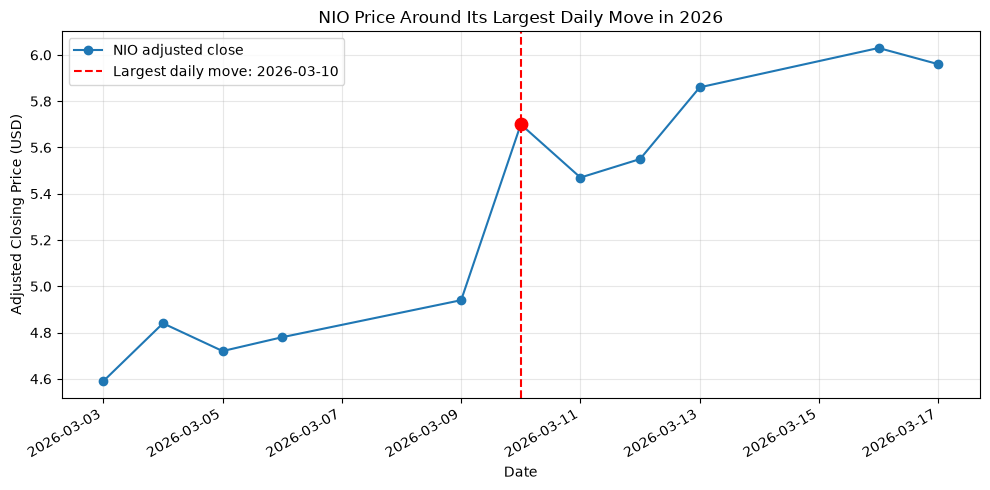

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    event_window.index,
    event_window["Close"],
    marker="o",
    label="NIO adjusted close"
)
ax.axvline(
    event_date,
    color="red",
    linestyle="--",
    label=f"Largest daily move: {event_date:%Y-%m-%d}"
)
ax.scatter(
    event_date,
    nio.loc[event_date, "Close"],
    color="red",
    s=80,
    zorder=5
)

ax.set_title("NIO Price Around Its Largest Daily Move in 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted Closing Price (USD)")
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Figure caption:** NIO's adjusted closing price around its largest absolute
daily return in the study period. The red dashed line marks March 10, 2026,
when the stock rose 15.38% from the previous trading day's close. The window
low is \$4.59 on March 3 and the window high is \$6.03 on March 16. The chart
shows that the jump was followed by several rising sessions rather than an
immediate reversal, which matters because it suggests the market was
re-pricing the company rather than reacting for a single day.